# Export a small layer with a contract

**Browser GIS · 15–25 minutes · learning companion**

Ten notebooks bridge browser GeoJSON/metadata exercises with RustGIS Web and separately documented native RustGIS.

**Learning question:** What must survive a GeoJSON handoff?

**Source project:** [JupyterLite-RustGIS](https://github.com/jltobias/JupyterLite-RustGIS).

This original index activity is **synthetic teaching analysis**. It uses invented values or authored metadata, no real people or sensitive locations, no remote APIs, and no AI model calls. It is a small companion to the source project, not a reproduction of that project's full course.

![Learning workflow](../../assets/capabilities.svg)

Original atlas diagram, James L. Tobias and contributors, CC BY 4.0; see [asset provenance](../../visual-provenance.ipynb).


## Predict before running

Build four fictional WGS84 points and inspect their bounding box and property coverage. GeoJSON coordinates use longitude, latitude; values do not describe actual places.

Write a prediction and one assumption you would need to check. Run cells in order with **Shift+Enter**, or **Run → Run All Cells**. The next cell defines only local SVG display helpers; the following cell performs the analysis. Every graphic also prints its values as a text alternative.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


WGS84 bounding box [west, south, east, north]: [20.0, -10.0, 20.3, -9.85]
Property coverage: {'id': {'present': 4, 'missing_ids': []}, 'value': {'present': 4, 'missing_ids': []}, 'units': {'present': 4, 'missing_ids': []}, 'origin': {'present': 4, 'missing_ids': []}, 'observation_status': {'present': 4, 'missing_ids': []}}
Portable GeoJSON bytes: 1458
Lab export: atlas-synthetic-rustgis.geojson - written in the kernel working folder; use the download below or locate this file in the Lab file browser.


Synthetic layer attributes | arbitrary index: {'T0': 1, 'T1': 2, 'T2': 3, 'T3': 4}


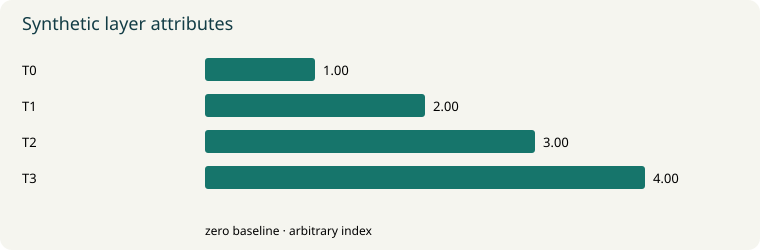

In [2]:
import json
from pathlib import Path
from base64 import b64encode
from IPython.display import HTML

features = [{'type':'Feature','geometry':{'type':'Point','coordinates':[20+i*.1, -10+i*.05]},'properties':{'id':f'T{i}','value':i+1,'units':'arbitrary index','origin':'synthetic','observation_status':'invented'}} for i in range(4)]
coordinates = [f['geometry']['coordinates'] for f in features]
bbox = [min(p[0] for p in coordinates), min(p[1] for p in coordinates),
        max(p[0] for p in coordinates), max(p[1] for p in coordinates)]
required_properties = ['id', 'value', 'units', 'origin', 'observation_status']
coverage = {key: {'present':sum(key in f['properties'] for f in features),
                  'missing_ids':[f['properties'].get('id', '(no id)') for f in features if key not in f['properties']]}
            for key in required_properties}
layer = {'type':'FeatureCollection','bbox':bbox,'features':features}
assert all(f['properties']['origin']=='synthetic' for f in features)
print('WGS84 bounding box [west, south, east, north]:', bbox)
print('Property coverage:', coverage)
payload = json.dumps(layer, indent=2).encode('utf-8')
export_path = Path('atlas-synthetic-rustgis.geojson')
export_path.write_bytes(payload)
print('Portable GeoJSON bytes:', len(payload))
print('Lab export:', export_path.name, '- written in the kernel working folder; use the download below or locate this file in the Lab file browser.')
encoded = b64encode(payload).decode('ascii')
display(HTML(f'<a download="atlas-synthetic-rustgis.geojson" href="data:application/geo+json;base64,{encoded}">Download the complete synthetic GeoJSON</a>'))
bars({f['properties']['id']:f['properties']['value'] for f in features}, 'Synthetic layer attributes', 'arbitrary index')

## Interpret the result

The layer preserves IDs, values and provenance, but a valid file does not guarantee an appropriate map projection, truthful location or safe disclosure.

Name the result, the assumption producing it, and one conclusion it cannot support. These are not clinical findings, causal effects or live model outputs.

## Change one thing

Inspect the bounding box and property-coverage report. Add a source_note field, then include it in required_properties to audit coverage. Import the downloaded synthetic layer into the source's RustGIS Web route, then verify fields after export.

Save a copy with **File → Save and Export Notebook As → Notebook** (or the file browser's Download command). Browser storage is local to this browser/profile; it is not a GitHub commit or shared database.


## Connect the idea

Compare this activity with another chapter on the same [learning path](../../index.ipynb). Keep the question, data status and interpretation visible when transferring a method.


## Sources, continuation and limits

**Source repository:** [JupyterLite-RustGIS](https://github.com/jltobias/JupyterLite-RustGIS).

**Source README:** [reviewed immutable version](https://github.com/jltobias/JupyterLite-RustGIS/blob/64ee4e32222c07006ab28a634b759d985a002bda/README.md); inspected 2026-11-01, commit `64ee4e32222c`. Repository content and linked works keep their original terms. Summaries and exercises here are newly authored.

RustGIS Python is native CPython; no native Rust package runs here. Official Web has its own limits. Optional STAC requests and local Ollama have network/origin requirements; the default is credential-free.

- [Run source Lab](https://jltobias.github.io/JupyterLite-RustGIS/lab/lab/index.html) - Run the source project notebooks; its dependencies and data terms apply. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Read source Book](https://jltobias.github.io/JupyterLite-RustGIS/book/index.html) - Read the original project course and its own source notes. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Explore source 2D map](https://jltobias.github.io/JupyterLite-RustGIS/maps/2d.html) - Explore the original companion map and check its layer provenance. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Explore source 3D map](https://jltobias.github.io/JupyterLite-RustGIS/maps/3d.html) - Explore original extruded geography; height encodings require interpretation. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Explore source 3D scene](https://jltobias.github.io/JupyterLite-RustGIS/maps/scene.html) - Orbit the original conceptual scene; graphics support may be required. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Open source explorer](https://jltobias.github.io/JupyterLite-STAC-Browser/explorer/) - Use the original interactive discovery or teaching explorer. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)

**Runtime budget:** this default is fewer than 100 values and normally completes within seconds; allow 60 seconds per cell while first loading Python. For native/GPU tools, use the source's local/server guide in an isolated environment, start with one small public/synthetic fixture, limit a trial to 5 minutes, and inspect memory, provider costs and outputs before scaling. For live models, use an approved authenticated backend with server-side secrets and a bounded single request; do not put credentials or sensitive records into a browser. Nothing in this chapter calls those services.

[Central references](../../references.ipynb) · [Contribute](../../contributor-guide.ipynb)
